# Lab 2: Classification Using KNN and RNN Algorithms

**Name:** Corey Hyde  
**Student ID:** 003044072  
**Course:** MSCS-634-A01 – Advanced Big Data and Data Mining  
**Assignment:** Lab 2

## 1. Purpose
This lab compares K-Nearest Neighbors (KNN) and Radius Neighbors (RNN) on the Wine dataset. I test the required neighbor counts and radii, plot their test accuracies, and discuss the differences. The experiments use original (unscaled) feature values to preserve the meaning of the assigned RNN radii.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

RANDOM_STATE = 42

## 2. Load and explore the Wine dataset

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="wine_class")
print("Dataset shape:", X.shape)
print("Feature names:", list(X.columns))
print("Class labels:", list(wine.target_names))
display(X.head())
display(X.describe().round(2))
print("Missing feature values:", int(X.isna().sum().sum()))
class_counts = y.value_counts().sort_index().rename(index=dict(enumerate(wine.target_names)))
print("Class distribution:")
display(class_counts.to_frame("count"))

Dataset shape: (178, 13)
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Class labels: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


Missing feature values: 0
Class distribution:


,count
wine_class,
class_0,59
class_1,71
class_2,48


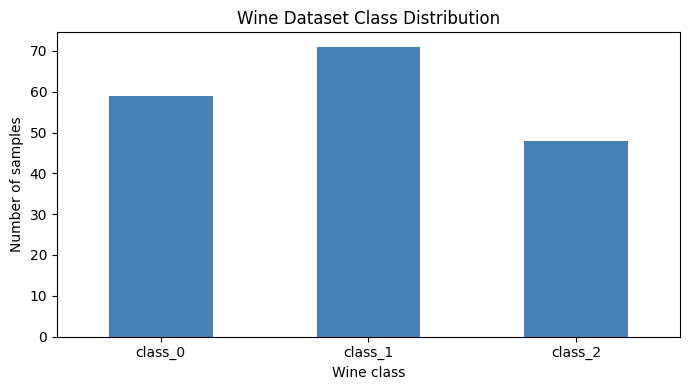

In [3]:
ax = class_counts.plot(kind="bar", figsize=(7, 4), color="steelblue")
ax.set(title="Wine Dataset Class Distribution", xlabel="Wine class", ylabel="Number of samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Split data into training and testing sets
I use an 80/20 stratified split with a fixed random seed. Stratification helps maintain the three-class distribution in both sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Testing class counts:", y_test.value_counts().sort_index().to_dict())

Training samples: 142
Testing samples: 36
Training class counts: {0: 47, 1: 57, 2: 38}
Testing class counts: {0: 12, 1: 14, 2: 10}


## 4. K-Nearest Neighbors (KNN)
KNN predicts the class using the majority vote of the nearest *k* training observations. I evaluate each requested value on the same test set.

In [5]:
k_values = [1, 5, 11, 15, 21]
knn_results = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    knn_results.append({"k": k, "accuracy": accuracy_score(y_test, predictions)})
knn_df = pd.DataFrame(knn_results)
display(knn_df.assign(accuracy_percent=lambda df: (df.accuracy * 100).round(2)))
best_knn_row = knn_df.loc[knn_df.accuracy.idxmax()]
print(f"Best KNN: k={int(best_knn_row.k)}, accuracy={best_knn_row.accuracy:.2%}")

,k,accuracy,accuracy_percent
0,1,0.777778,77.78
1,5,0.805556,80.56
2,11,0.805556,80.56
3,15,0.805556,80.56
4,21,0.805556,80.56


Best KNN: k=5, accuracy=80.56%


## 5. Radius Neighbors (RNN)
Radius Neighbors votes among training observations within the specified distance radius. If a test observation has no neighbors, I use the most frequent training class as a fallback (`outlier_label="most_frequent"`) so every test observation receives a prediction. I also count observations with no neighbors to make this decision transparent.

In [6]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_results = []
for radius in radius_values:
    model = RadiusNeighborsClassifier(radius=radius, outlier_label="most_frequent")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    neighbor_counts = [len(indices) for indices in model.radius_neighbors(X_test, return_distance=False)]
    rnn_results.append({"radius": radius, "accuracy": accuracy_score(y_test, predictions),
                        "test_samples_without_neighbors": sum(count == 0 for count in neighbor_counts)})
rnn_df = pd.DataFrame(rnn_results)
display(rnn_df.assign(accuracy_percent=lambda df: (df.accuracy * 100).round(2)))
best_rnn_row = rnn_df.loc[rnn_df.accuracy.idxmax()]
print(f"Best RNN: radius={int(best_rnn_row.radius)}, accuracy={best_rnn_row.accuracy:.2%}")

,radius,accuracy,test_samples_without_neighbors,accuracy_percent
0,350,0.722222,0,72.22
1,400,0.694444,0,69.44
2,450,0.694444,0,69.44
3,500,0.694444,0,69.44
4,550,0.666667,0,66.67
5,600,0.666667,0,66.67


Best RNN: radius=350, accuracy=72.22%


## 6. Visualize accuracy trends

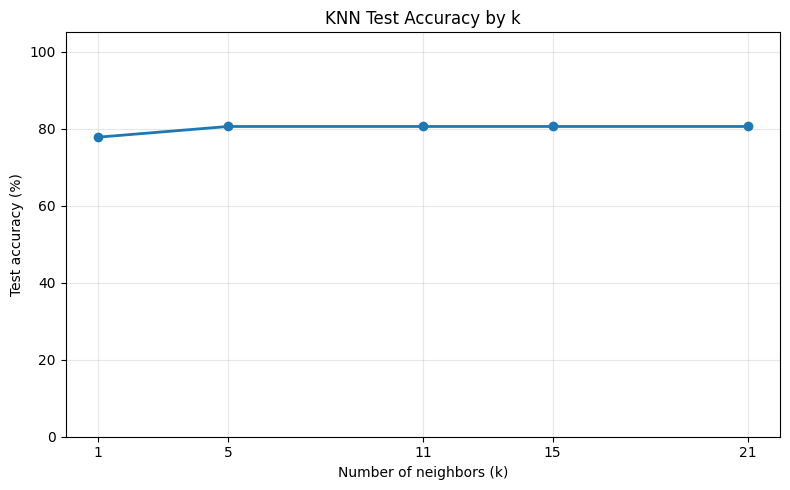

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(knn_df.k, knn_df.accuracy * 100, marker="o", linewidth=2)
plt.xticks(k_values)
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Test accuracy (%)")
plt.title("KNN Test Accuracy by k")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("knn_accuracy.png", dpi=150)
plt.show()

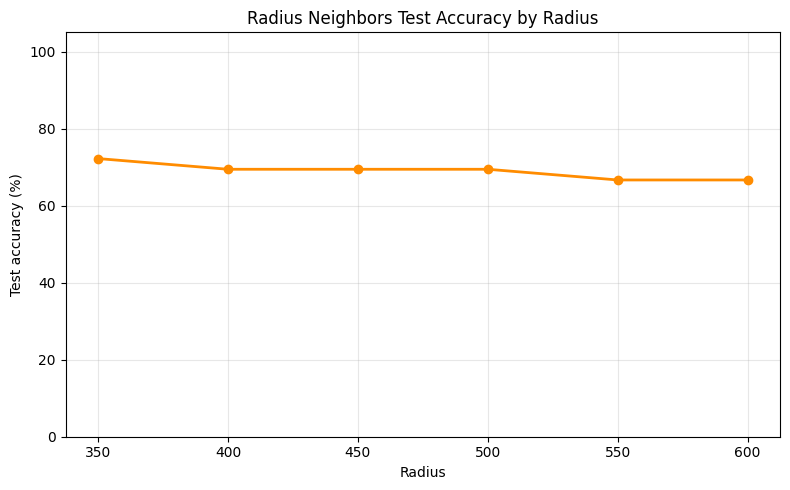

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(rnn_df.radius, rnn_df.accuracy * 100, marker="o", linewidth=2, color="darkorange")
plt.xticks(radius_values)
plt.xlabel("Radius")
plt.ylabel("Test accuracy (%)")
plt.title("Radius Neighbors Test Accuracy by Radius")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("rnn_accuracy.png", dpi=150)
plt.show()

## 7. Compare models

In [9]:
comparison = pd.DataFrame([
    {"model": "KNN", "best_parameter": f"k={int(best_knn_row.k)}", "test_accuracy": best_knn_row.accuracy},
    {"model": "RNN", "best_parameter": f"radius={int(best_rnn_row.radius)}", "test_accuracy": best_rnn_row.accuracy},
])
display(comparison)
print("Accuracy difference (KNN minus RNN):", f"{(best_knn_row.accuracy - best_rnn_row.accuracy)*100:.2f} percentage points")
print("KNN accuracy range:", f"{knn_df.accuracy.min():.2%} to {knn_df.accuracy.max():.2%}")
print("RNN accuracy range:", f"{rnn_df.accuracy.min():.2%} to {rnn_df.accuracy.max():.2%}")

,model,best_parameter,test_accuracy
0,KNN,k=5,0.805556
1,RNN,radius=350,0.722222


Accuracy difference (KNN minus RNN): 8.33 percentage points
KNN accuracy range: 77.78% to 80.56%
RNN accuracy range: 66.67% to 72.22%


## 8. Observations and conclusion
The tables and plots above show how test accuracy changes with the neighbor count or radius. A smaller **k** relies on very local examples and can be sensitive to noise, while larger **k** values average over more observations and can blur class boundaries. RNN instead uses a fixed distance, so the number of neighbors varies from one sample to another. Large radii may mix different wine classes; small radii can leave observations without neighbors.

**My comparison:** The best settings and their measured test accuracies are printed above. For this particular train/test split, I would prefer the method with the higher measured accuracy, while recognizing that selecting parameters on the test set can produce an optimistic estimate. In a larger project, I would choose parameters through cross-validation on the training data and evaluate the final selection once on a separate test set.

**When to use each method:** KNN is a straightforward choice when every prediction should use a fixed number of nearby observations. RNN can be useful when a meaningful distance threshold exists and sample density varies, but its radius and handling of samples without neighbors require care.

**Limitations and decisions:** The chemical features have very different numeric scales. I kept the original scales to match the specified radii, but features with large ranges can dominate Euclidean distance. For a fairer modeling study, I would also compare standardized features with newly tuned radii. This dataset is relatively small (178 samples), so results depend on the split. Accuracy alone does not show which wine classes are confused.

## References
- scikit-learn developers. *Wine recognition dataset*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html
- scikit-learn developers. *Nearest Neighbors*. https://scikit-learn.org/stable/modules/neighbors.html